<a href="https://colab.research.google.com/github/bhavya1101-cse/aiml-2026-iiith-ihub/blob/main/AIML_Module_2_Lab_3B_t_SNE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 2: Appreciating, Interpreting and Visualizing Data
## Lab 3B: t-Distributed Stochastic Neighbor Embedding (t-SNE)

---



This lab will be based upon t-SNE which is a dimensionality reduction algorithm used to visualize high dimensional datasets.

t-SNE stands for t-Distributed Stochastic Neighbor Embedding. It is an unsupervised, non-linear technique primarily used for data exploration and visualizing high-dimensional data. It was developed by Laurens van der Maatens and Geoffrey Hinton in 2008 (Link to the paper: https://www.jmlr.org/papers/volume9/vandermaaten08a/vandermaaten08a.pdf)

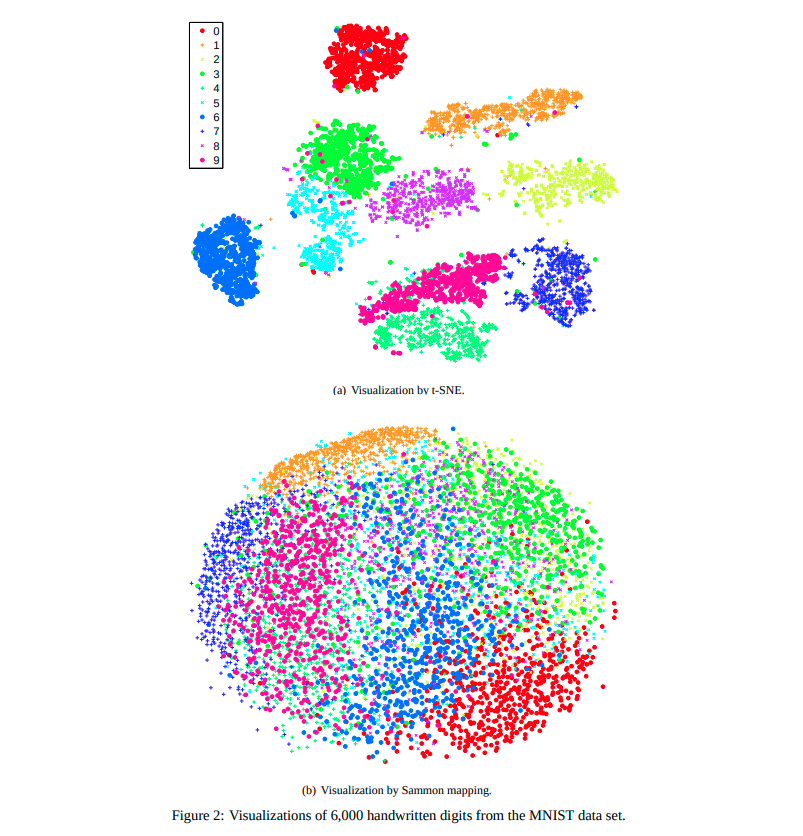

**What is t-SNE? (Simplified)**

- t-SNE is like a "magic map" for data. Imagine you have a huge, complex 3D sculpture, and you want to draw it on a flat piece of paper. t-SNE helps you draw it in a way that keeps the important relationships between parts of the sculpture intact.
- It’s non-linear, meaning it can capture curves, twists, and clusters that linear methods (like PCA) might miss.

**Why Use t-SNE?**

- Visualization: Helps you "see" high-dimensional data in 2D or 3D.
- Exploration: Useful for spotting patterns, clusters, or outliers in data.
- Preprocessing: Sometimes used before clustering algorithms to get a sense of how many clusters might exist

t-SNE has a tuneable parameter, **perplexity** which balances attention between the local and global aspects of your data. It is a guess about the number of close neighbors each point has. The perplexity value has a complex effect on the resulting pictures. The original paper says, “The performance of t-SNE is fairly robust to changes in the perplexity, and typical values are between 5 and 50.” But the story is more nuanced than that. Getting the most from t-SNE may mean analyzing multiple plots with different perplexities.

Also the t-SNE algorithm doesn’t always produce similar output on successive runs as there are additional hyperparameters related to the optimization process.

**What is Perplexity? (Simplified)**

Perplexity is like a "knob" that controls how t-SNE balances attention between local and global patterns in your data.
- Low perplexity (e.g., 5): t-SNE focuses on tiny, local clusters. Good for detailed, fine-grained structure.
- High perplexity (e.g., 50): t-SNE looks at broader, global patterns. Good for seeing the "big picture."

**Example: Choosing Perplexity**

- If your dataset has 500 points, try perplexity values between 5 and 50.
- If you set perplexity to 200, t-SNE might get confused because it’s trying to consider too many neighbors at once.

### HOW DOES T-SNE WORK??

The t-SNE algorithm calculates a similarity measure between pairs of instances in the high dimensional space and in the low dimensional space. It then tries to optimize these two similarity measures using a cost function. Let’s break that down into 3 basic steps.

1. Measure similarities between points in the high dimensional space. Think of a bunch of data points scattered on a 2D space. For each data point (xi) we’ll center a Gaussian distribution over that point. Then we measure the density of all points (xj) under that Gaussian distribution. Then renormalize for all points. This gives us a set of probabilities (Pij) for all points. Those probabilities are proportional to the similarities. All that means is, if data points x1 and x2 have equal values under this gaussian circle then their proportions and similarities are equal and hence you have local similarities in the structure of this high-dimensional space. The Gaussian distribution or circle can be manipulated using what’s called perplexity, which influences the variance of the distribution (circle size) and essentially the number of nearest neighbors.

2. This step is similar to step 1, but instead of using a Gaussian distribution we use a Student t-distribution with one degree of freedom, which is also known as the Cauchy distribution (See fig below). This gives us a second set of probabilities (Qij) in the low dimensional space. As you can see the Student t-distribution has heavier tails than the normal distribution. The heavy tails allow for better modeling of far apart distances.

3. The last step is that we want these set of probabilities from the low-dimensional space (Qij) to reflect those of the high dimensional space (Pij) as best as possible. We want the two map structures to be similar. We measure the difference between the probability distributions of the two-dimensional spaces using Kullback-Liebler divergence (KL). Finally, we use gradient descent to minimize our KL cost function.

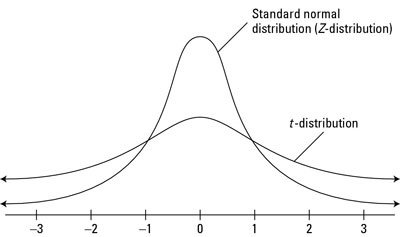

**Analogy: t-SNE as a "Social Network"**

Imagine your data points are people at a party.

- Step 1: In the "real world" (high-dimensional space), you measure how close people are standing (using a Gaussian distribution).
- Step 2: You try to rearrange everyone in a smaller room (2D/3D space) so that the distances between friends (similar points) stay the same.
- Step 3: You use a "cost function" (KL divergence) to measure how well you’ve preserved these relationships. The goal is to minimize this cost.

Scikit-learn has an implementation of t-SNE available which provides a wide variety of tuning parameters for t-SNE, and the most notable ones are:

1. n_components (default: 2): Dimension of the embedded space.
2. perplexity (default: 30): The perplexity is related to the number of nearest neighbors that are used in other manifold learning algorithms. Consider selecting a value between 5 and 50.
3. n_iter (default: 1000): Maximum number of iterations for the optimization. Should be at least 250.
4. method (default: ‘barnes_hut’): Barnes-Hut approximation runs in O(NlogN) time. method=’exact’ will run on the slower, but exact, algorithm in O(N^2) time.

**Tips for Using sklearn.manifold.TSNE**

- n_components: Usually 2 (for 2D plots) or 3 (for 3D).
- perplexity: Start with 30. Adjust based on your dataset size.
- n_iter: Start with 1000. Increase if the plot looks unstable.
- method: Use 'barnes_hut' for large datasets (faster). Use 'exact' for small datasets (more accurate).

In [ ]:
# numpy.
import numpy as np
from numpy import linalg
from numpy.linalg import norm
from scipy.spatial.distance import squareform, pdist

# sklearn.
import sklearn
from sklearn.manifold import TSNE
from sklearn.datasets import load_digits
from sklearn.preprocessing import scale

# Random state.
RS = 20150101

# matplotlib.
import matplotlib.pyplot as plt
import matplotlib.patheffects as PathEffects
import matplotlib
%matplotlib inline

# seaborn.
import seaborn as sns
sns.set_style('darkgrid')
sns.set_palette('muted')
sns.set_context("notebook", font_scale=1.5,
                rc={"lines.linewidth": 2.5})

1797 images each of size 8 x 8 loaded using load_digits()

In [ ]:
digits = load_digits()
digits.data.shape

(1797, 64)

Printing some images from the dataset

---



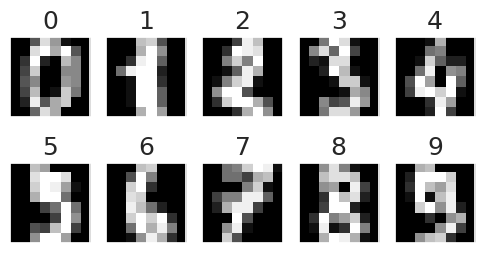

In [ ]:
nrows, ncols = 2, 5
plt.figure(figsize=(6,3))
plt.gray()
for i in range(ncols * nrows):
    ax = plt.subplot(nrows, ncols, i + 1)
    ax.matshow(digits.images[i,...])
    plt.xticks([]); plt.yticks([])
    plt.title(digits.target[i])

**Interpreting the MNIST t-SNE Plot**

Each color represents a digit (0-9).
Clusters: Digits that are similar (e.g., 4 and 9) might appear closer together.
Outliers: Points far from their cluster might be miswritten digits or anomalies.

**Exercise: Try This!**

Run t-SNE on a subset of MNIST (e.g., only digits 3, 5, and 8).
Observe how the clusters change when you adjust perplexity from 5 to 50.



In [ ]:
# We first reorder the data points according to the handwritten numbers.
X = np.vstack([digits.data[digits.target==i]
               for i in range(10)])
y = np.hstack([digits.target[digits.target==i]
               for i in range(10)])

## Now using TSNE to fit the dataset with the default values.


1. n_components : 2
2. perplexity : 30
3. n_iter : 1000
4. method : ‘barnes_hut’


---



In [ ]:
digits_proj = TSNE(init="pca", random_state=RS).fit_transform(X)

#### Visualizing the data in the projected space

---



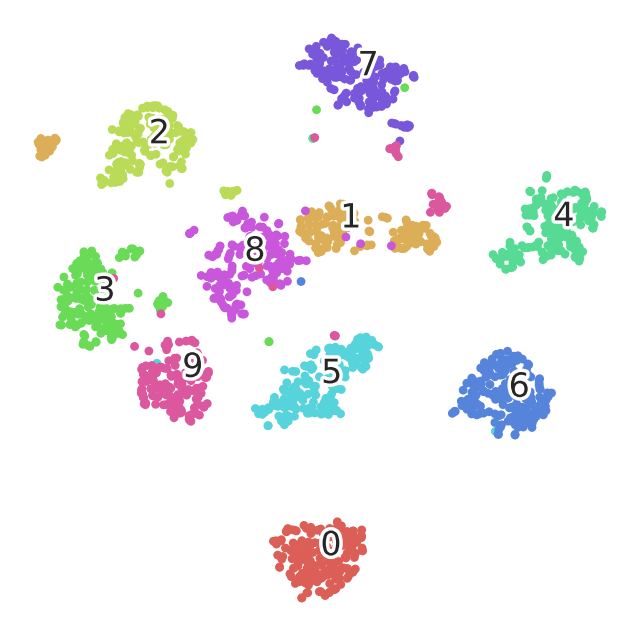

(<Figure size 800x800 with 1 Axes>,
 <Axes: >,
 <matplotlib.collections.PathCollection at 0x7e1c36ac4830>)

In [ ]:
def scatter(x, colors):
    # We choose a color palette with seaborn.
    palette = np.array(sns.color_palette("hls", 10))

    # We create a scatter plot.
    f = plt.figure(figsize=(8, 8))
    ax = plt.subplot(aspect='equal')
    sc = ax.scatter(x[:,0], x[:,1], lw=0, s=40,
                    c=palette[colors.astype(int)])
    plt.xlim(-25, 25)
    plt.ylim(-25, 25)
    ax.axis('off')
    ax.axis('tight')

    # We add the labels for each digit.
    txts = []
    for i in range(10):
        # Position of each label.
        xtext, ytext = np.median(x[colors == i, :], axis=0)
        txt = ax.text(xtext, ytext, str(i), fontsize=24)
        txt.set_path_effects([
            PathEffects.Stroke(linewidth=5, foreground="w"),
            PathEffects.Normal()])
        txts.append(txt)
    plt.show()

    return f, ax, sc

scatter(digits_proj, y)

# Tweaking some of the hyperparameters to better understand their role

---

### Changing the PERPLEXITY values


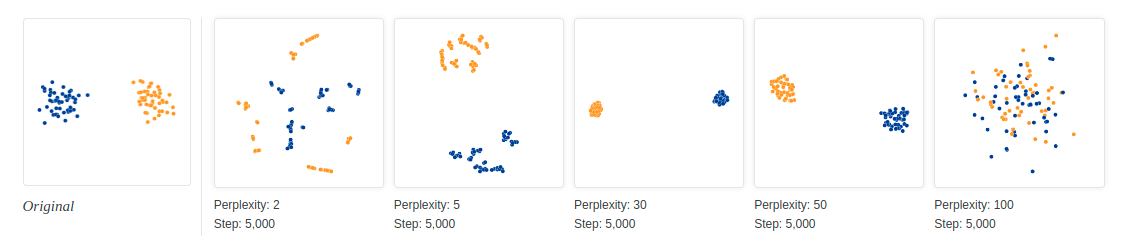

With perplexity values in the range (5 - 50) suggested by van der Maaten & Hinton, the diagrams do show these clusters, although with very different shapes. Outside that range, things get a little weird. With perplexity 2, local variations dominate. The image for perplexity 100, with merged clusters, illustrates a pitfall: for the algorithm to operate properly, the perplexity really should be smaller than the number of points. Implementations can give unexpected behavior otherwise.



---


1. n_components : 2
2. perplexity : **5**
3. n_iter : 1000
4. method : ‘barnes_hut’


---

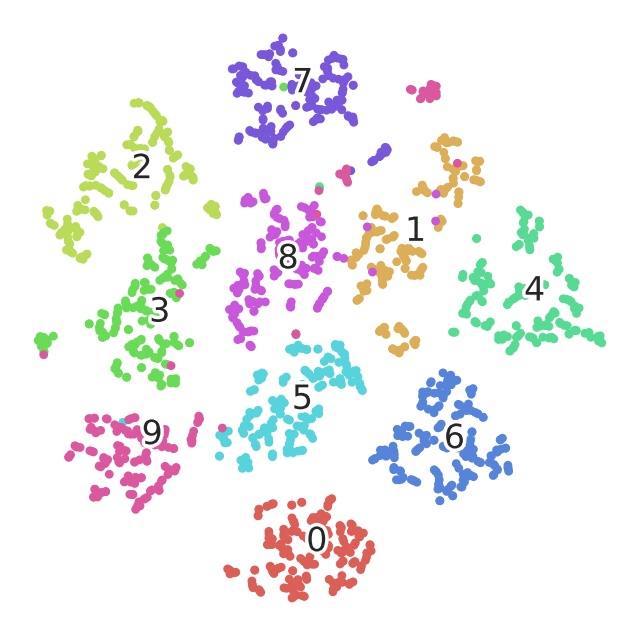

(<Figure size 800x800 with 1 Axes>,
 <Axes: >,
 <matplotlib.collections.PathCollection at 0x7e1c34718f50>)

In [ ]:
digits_proj = TSNE(init="pca", random_state=RS, perplexity=5).fit_transform(X)

scatter(digits_proj, y)

We can see that there are local clusters within the same number group as well. This is happening as the perplexity being at 5, allows the local neighbourhood to dominate. Let us now see what happens if we increase the perplexity to 100, thereby increasing global impact.





---


1. n_components : 2
2. perplexity : **100**
3. n_iter : 1000
4. method : ‘barnes_hut’


---

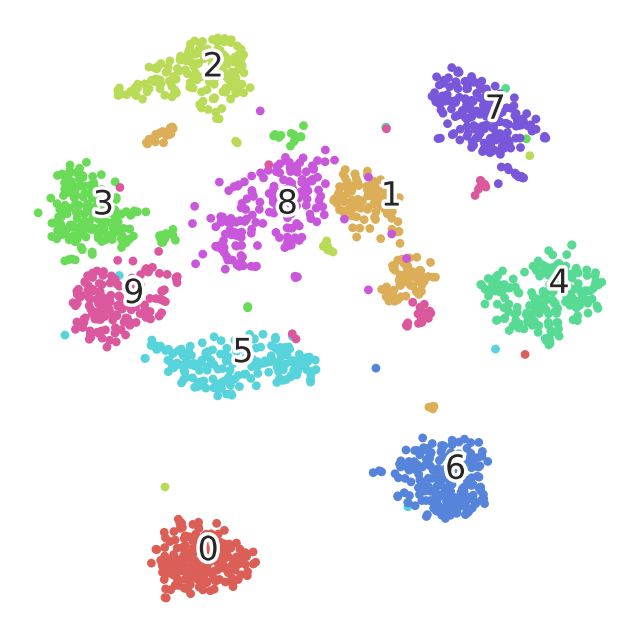

(<Figure size 800x800 with 1 Axes>,
 <Axes: >,
 <matplotlib.collections.PathCollection at 0x7e1c3474d090>)

In [ ]:
digits_proj = TSNE(init="pca", random_state=RS, perplexity=100).fit_transform(X)

scatter(digits_proj, y)

The general structure of the plot remained similar to the one with perplexity = 30 (default), but on careful observation you can observe many data points not being part of the group they are supposed to be in. This is because of the large number of points considered for the neighbourhood (as perplexity value = 100 is higher), thereby allowing 2 data points from different groups to end up closer.



---

### Changing the NUMBER OF ITERATIONS

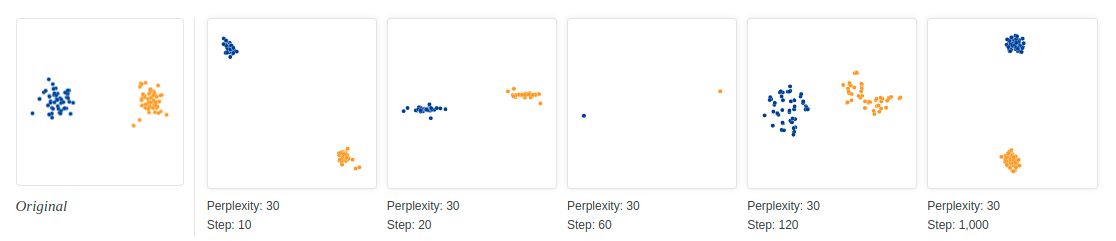

The images above show five different runs at perplexity 30. The first four were stopped before stability. After 10, 20, 60, and 120 steps you can see layouts with seeming 1-dimensional and even pointlike images of the clusters. If you see a t-SNE plot with strange “pinched” shapes, chances are the process was stopped too early. Unfortunately, there’s no fixed number of steps that yields a stable result. Different data sets can require different numbers of iterations to converge.

The most important thing is to iterate until reaching a stable configuration.





---


1. n_components : 2
2. perplexity : 30
3. n_iter : **250**
4. method : ‘barnes_hut’


---

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


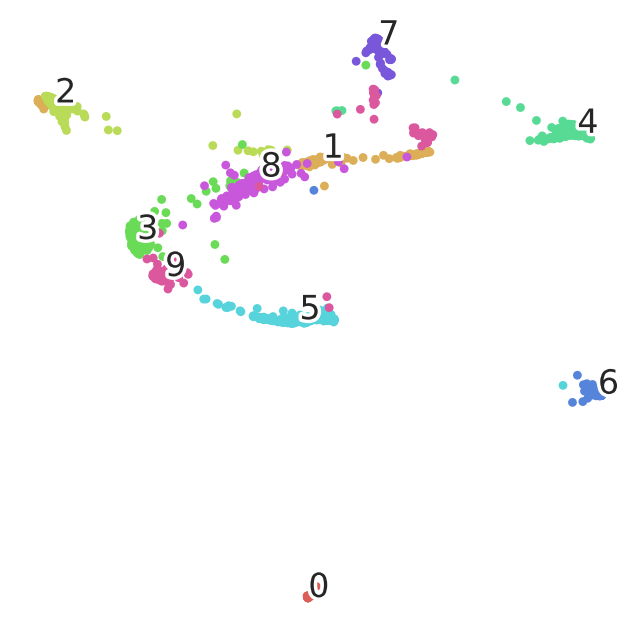

(<Figure size 800x800 with 1 Axes>,
 <Axes: >,
 <matplotlib.collections.PathCollection at 0x7e1c3479d1d0>)

In [ ]:
digits_proj = TSNE(init="pca", random_state=RS, n_iter=250).fit_transform(X)

scatter(digits_proj, y)

As can be seen from the figure above, stopping the optimization earlier (in 250 iterations) resulted in a suboptimal clustering of the groups.

Let us now see how the results are affected if t-SNE is run for larger number of iterations


---


1. n_components : 2
2. perplexity : 30
3. n_iter : **5000**
4. method : ‘barnes_hut’


---

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


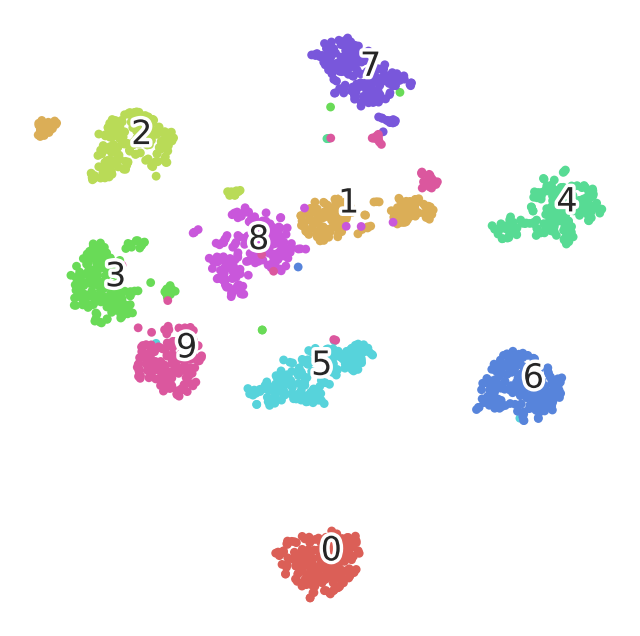

(<Figure size 800x800 with 1 Axes>,
 <Axes: >,
 <matplotlib.collections.PathCollection at 0x7e1c347f1310>)

In [ ]:
digits_proj = TSNE(init="pca", random_state=RS, n_iter=5000).fit_transform(X)

scatter(digits_proj, y)

Running for larger number of iterations more or less resulted in the same plot as the optimization had nearly converged till the default 1000 iterations. However the density of the clusters has increased.

---

### Changing the method to EXACT

The barnes-hut method takes O(NlogN) time, whereas the exact method takes O(N^2) time. Notice the increase in the execution time while running the cell below.


---

1. n_components : 2
2. perplexity : 30
3. n_iter : 1000
4. method : **‘exact’**


---

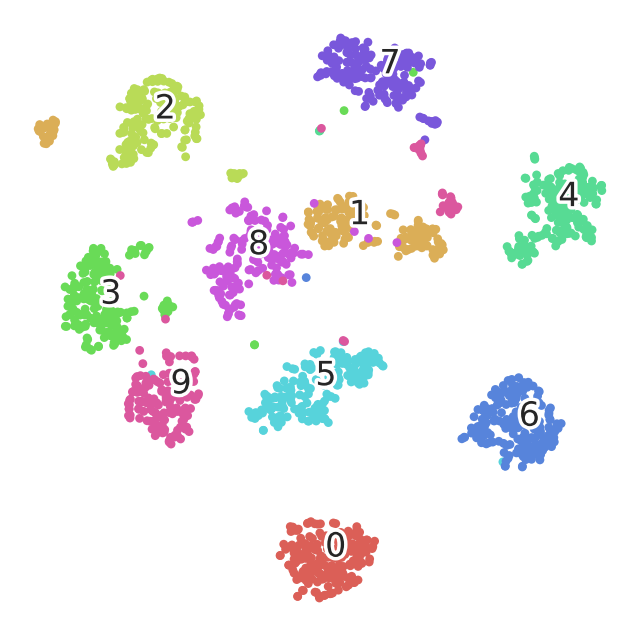

(<Figure size 800x800 with 1 Axes>,
 <Axes: >,
 <matplotlib.collections.PathCollection at 0x7e1c30e3d450>)

In [ ]:
digits_proj = TSNE(init="pca", random_state=RS, method='exact').fit_transform(X)

scatter(digits_proj, y)

## EXERCISE

---



Try out different perplexity and iteration values to better appreciate the concepts taught.

You can modify the code in the cell below to check the resultant plots.

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


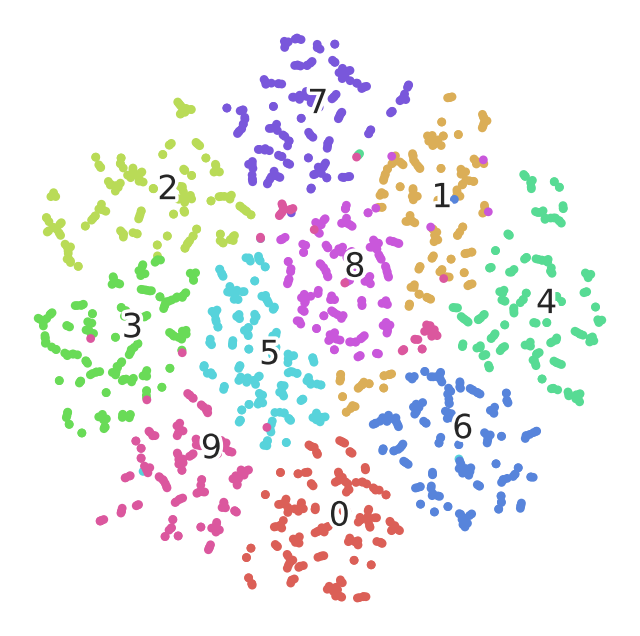

(<Figure size 800x800 with 1 Axes>,
 <Axes: >,
 <matplotlib.collections.PathCollection at 0x7e1c30e8d590>)

In [ ]:
###############################################################
###### MODIFY THE VALUES FOR THE HYPERPARAMETERS BELOW ########

perplexity_value = 2
number_iterations = 1000
method = "barnes_hut"

###############################################################

digits_proj = TSNE(init="pca", random_state=RS, n_iter=number_iterations, perplexity=perplexity_value, method=method).fit_transform(X)
scatter(digits_proj, y)

### My experiments with perplexity and iterations

Instead of changing the values one at a time, the cell below tries **5 perplexity values × 2 iteration counts** and shows all 10 results in one grid.

To compare them with a number as well as by eye, I measure **cluster quality**: a simple k-nearest-neighbour classifier (5 neighbours, 5-fold cross-validation) tries to predict each point's digit **using only its 2D t-SNE position**. If the digits form clean, separate clusters, this accuracy is close to 100%.

*Note: newer scikit-learn versions renamed `n_iter` to `max_iter` (that's the `FutureWarning` in the cells above), so I use `max_iter` here.*

perplexity=  2 | iterations= 250 | cluster quality= 98.3% | time= 1.0s


perplexity=  5 | iterations= 250 | cluster quality= 98.2% | time= 1.0s


perplexity= 30 | iterations= 250 | cluster quality= 96.9% | time= 1.5s


perplexity= 50 | iterations= 250 | cluster quality= 93.0% | time= 1.7s


perplexity=100 | iterations= 250 | cluster quality= 83.4% | time= 2.6s


perplexity=  2 | iterations=1000 | cluster quality= 96.5% | time= 4.1s


perplexity=  5 | iterations=1000 | cluster quality= 98.3% | time= 4.6s


perplexity= 30 | iterations=1000 | cluster quality= 97.6% | time= 5.0s


perplexity= 50 | iterations=1000 | cluster quality= 97.3% | time= 5.2s


perplexity=100 | iterations=1000 | cluster quality= 96.6% | time= 7.1s


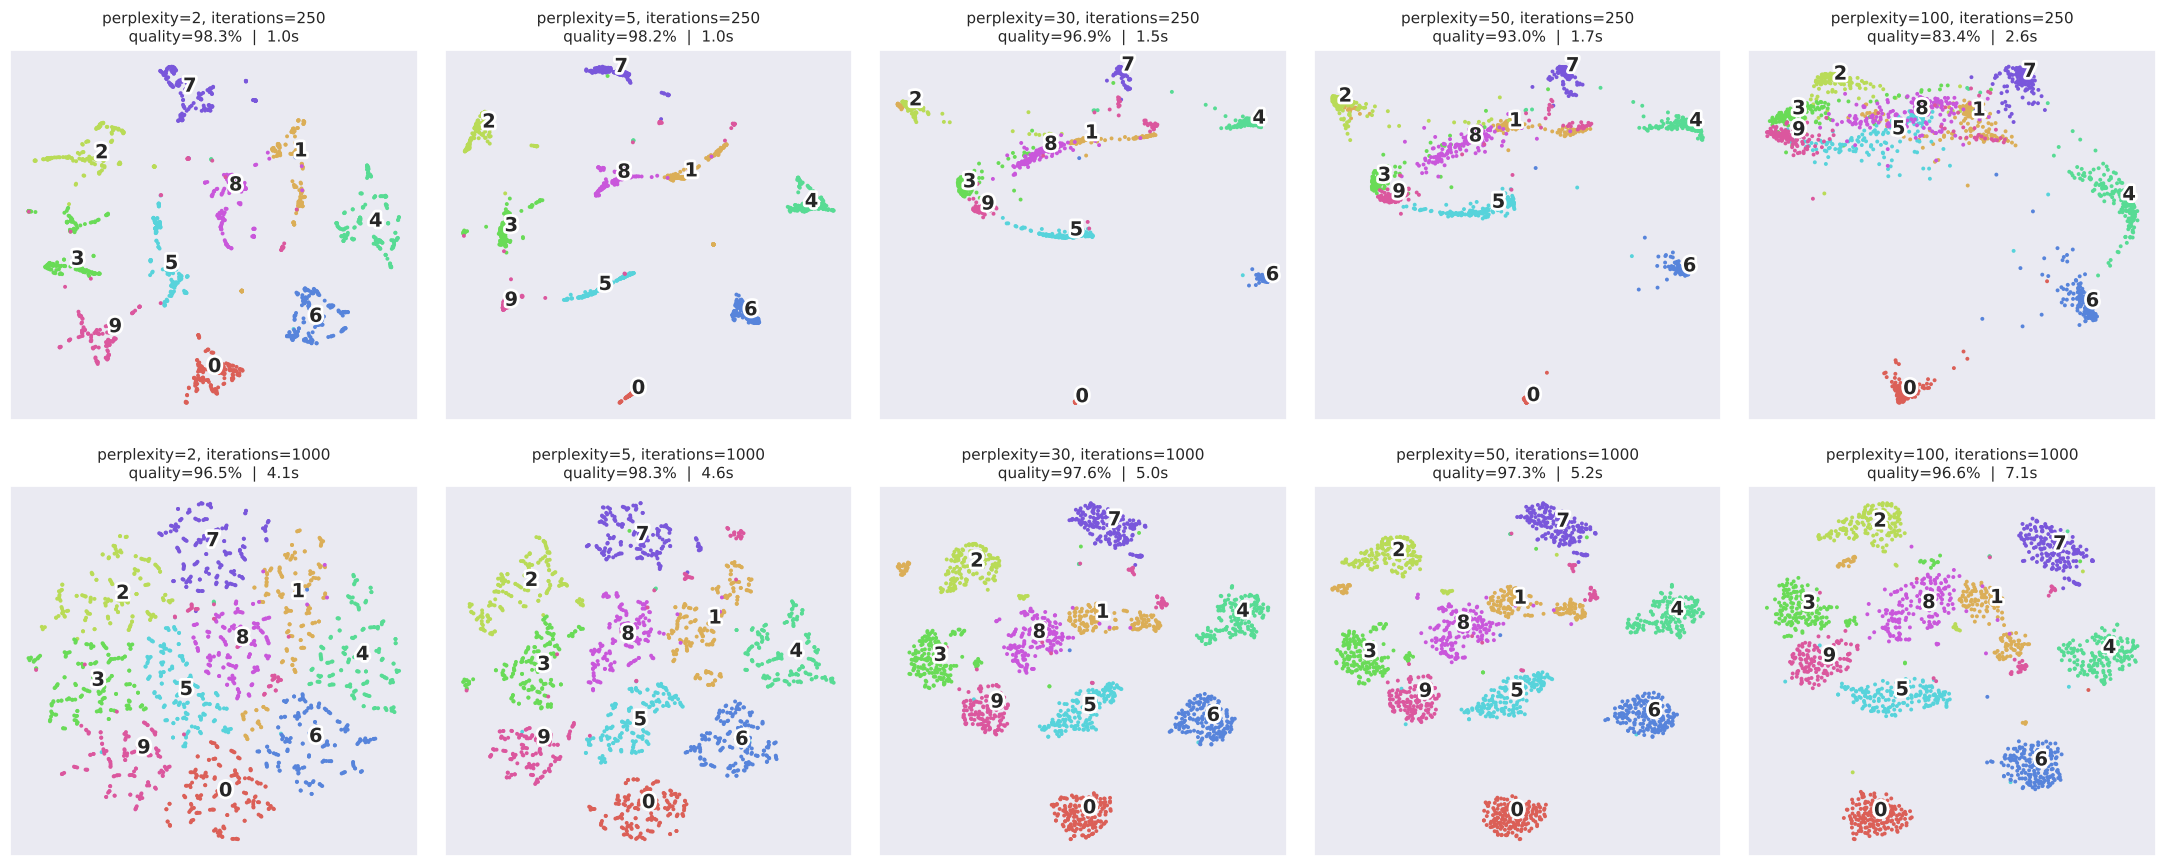

In [ ]:
import time
import warnings
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

warnings.filterwarnings("ignore")
palette = np.array(sns.color_palette("hls", 10))

def cluster_quality(points, labels):
    """Accuracy of a 5-NN classifier using only the 2D positions (higher = cleaner clusters)."""
    return cross_val_score(KNeighborsClassifier(n_neighbors=5), points, labels, cv=5).mean()

def small_scatter(ax, points, labels, title):
    """Smaller version of scatter() that draws into one subplot."""
    ax.scatter(points[:, 0], points[:, 1], lw=0, s=8, c=palette[labels.astype(int)])
    for d in np.unique(labels):
        xt, yt = np.median(points[labels == d], axis=0)
        t = ax.text(xt, yt, str(d), fontsize=14, weight="bold")
        t.set_path_effects([PathEffects.Stroke(linewidth=4, foreground="w"), PathEffects.Normal()])
    ax.set_title(title, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])

perplexities = [2, 5, 30, 50, 100]
iterations = [250, 1000]

fig, axes = plt.subplots(len(iterations), len(perplexities), figsize=(22, 9))
for r, n_it in enumerate(iterations):
    for c, perp in enumerate(perplexities):
        start = time.time()
        proj = TSNE(init="pca", random_state=RS, perplexity=perp, max_iter=n_it).fit_transform(X)
        secs = time.time() - start
        q = cluster_quality(proj, y)
        small_scatter(axes[r, c], proj, y, f"perplexity={perp}, iterations={n_it}\nquality={q*100:.1f}%  |  {secs:.1f}s")
        print(f"perplexity={perp:>3} | iterations={n_it:>4} | cluster quality={q*100:5.1f}% | time={secs:4.1f}s")

plt.tight_layout()
plt.show()

**What I observed:**

| Perplexity | 250 iterations | 1000 iterations |
|---|---|---|
| 2 | 98.3% (thin broken pieces) | 96.5% (one big round cloud, no gaps between digits) |
| 5 | 98.2% (thin streaks) | 98.3% (loose groups) |
| 30 (default) | 96.9% (squashed lines) | **97.6% (clean, round, well-separated clusters)** |
| 50 | 93.0% (squashed, some touching) | 97.3% (clean clusters) |
| 100 | 83.4% (several digits merged together) | 96.6% (clean, but some digits closer together) |

**Effect of perplexity:**
- **Very low (2):** t-SNE only looks at 1–2 neighbours per point. With 1000 iterations the points spread out into one big round cloud with no clear gaps, so you can't easily see where one digit ends and the next begins. Local details dominate and the bigger picture is lost.
- **Low (5):** the groups appear, but they're loose and some digits break into several small sub-groups (e.g. digit 1).
- **Medium (30–50):** the best pictures. Each digit forms one tight, round cluster with clear empty space between clusters. This matches the paper's advice of 5–50.
- **High (100):** each point considers about 100 neighbours, so similar-looking digits (1, 8, 5, 9, 3) are pulled closer together. With only 250 iterations they actually **merge** (quality drops to 83.4%).

**Effect of iterations:**
- **250 iterations:** the first 250 steps of scikit-learn's t-SNE are an "early exaggeration" phase that pushes clusters apart. Stopping right there leaves **pinched, line-like, squashed clusters**, exactly the "stopped too early" problem the lab describes. The quality numbers are still fairly high for small perplexities, but the shapes and sizes of clusters are misleading.
- **1000 iterations:** the layout has settled into a stable shape, with round clusters at sensible sizes. More iterations (like the 5000 in the lab) barely change it further.

**Conclusion:** perplexity around **30** with at least **1000 iterations** gave the clearest result for this dataset. Always try a few perplexity values and make sure the optimisation has run long enough before trusting a t-SNE plot.

---
### Exercise: Try This! (from the start of the lab)
**Run t-SNE on a subset of MNIST (e.g., only digits 3, 5, and 8). Observe how the clusters change when you adjust perplexity from 5 to 50.**

Digits 3, 5 and 8 are a good test because they look alike (curvy shapes with similar strokes).

Images of digits 3, 5 and 8: 539
PCA             | cluster quality= 91.8%


t-SNE perp=  5 | cluster quality= 99.8%


t-SNE perp= 15 | cluster quality= 99.8%


t-SNE perp= 30 | cluster quality= 99.6%


t-SNE perp= 50 | cluster quality= 98.5%


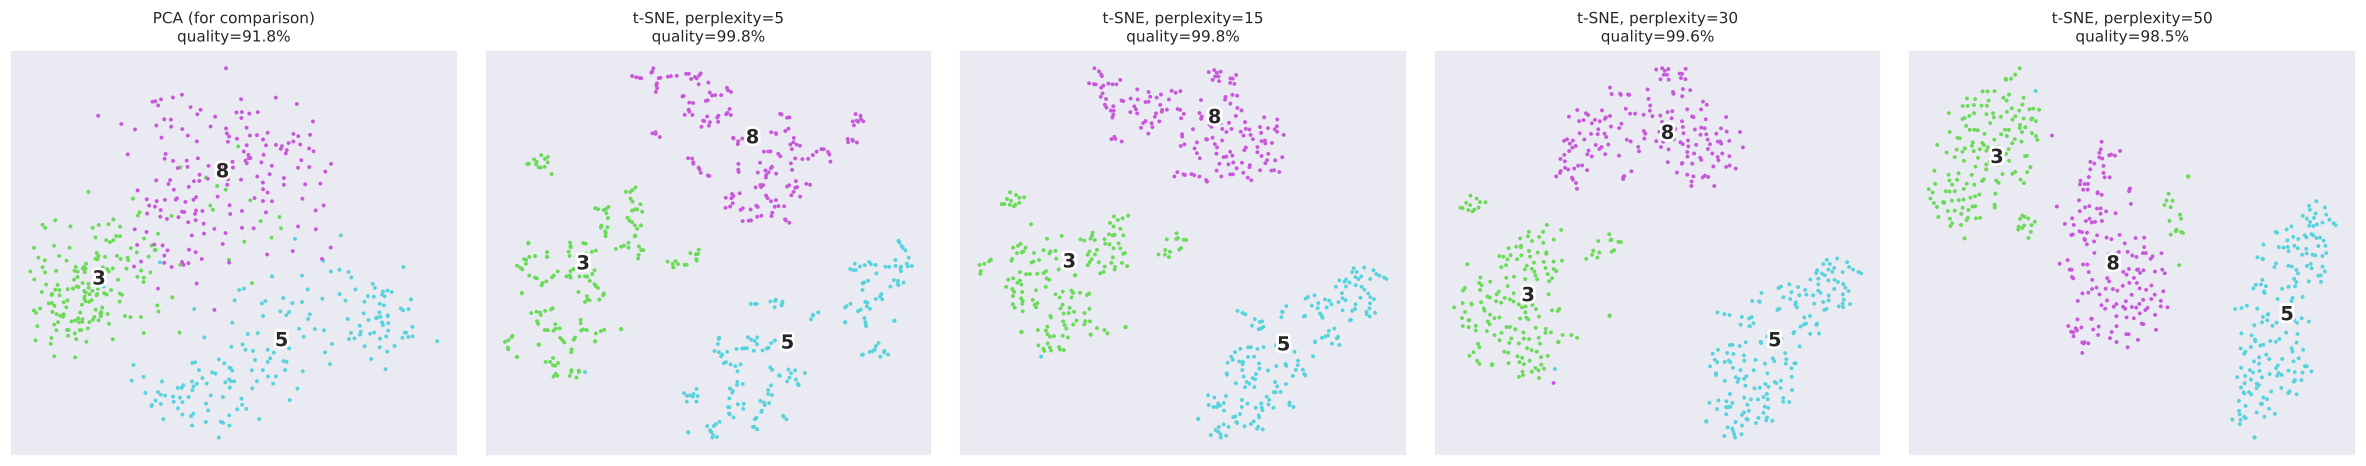

In [ ]:
subset_mask = np.isin(y, [3, 5, 8])
X_sub, y_sub = X[subset_mask], y[subset_mask]
print("Images of digits 3, 5 and 8:", len(y_sub))

from sklearn.decomposition import PCA
sub_perplexities = [5, 15, 30, 50]

fig, axes = plt.subplots(1, len(sub_perplexities) + 1, figsize=(24, 5))
pca_sub = PCA(n_components=2).fit_transform(X_sub)
small_scatter(axes[0], pca_sub, y_sub, f"PCA (for comparison)\nquality={cluster_quality(pca_sub, y_sub)*100:.1f}%")
print(f"PCA             | cluster quality={cluster_quality(pca_sub, y_sub)*100:5.1f}%")

for ax, perp in zip(axes[1:], sub_perplexities):
    proj = TSNE(init="pca", random_state=RS, perplexity=perp).fit_transform(X_sub)
    q = cluster_quality(proj, y_sub)
    small_scatter(ax, proj, y_sub, f"t-SNE, perplexity={perp}\nquality={q*100:.1f}%")
    print(f"t-SNE perp={perp:>3} | cluster quality={q*100:5.1f}%")

plt.tight_layout()
plt.show()

**What I observed:**

- **PCA (91.8%)**: the three digits form rough areas, but 8 overlaps with both 3 and 5 along the borders, because 8 shares strokes with both.
- **t-SNE, perplexity 5 (99.8%)**: the three digits are fully separated, but each digit is broken into **several small sub-clusters** (e.g. small separate islands of 3s). Low perplexity focuses on very local similarity, so different handwriting styles of the same digit form their own little groups.
- **t-SNE, perplexity 15 and 30 (99.8%, 99.6%)**: three clean, compact clusters with clear gaps between them. Only a few small islands remain. This is the clearest view.
- **t-SNE, perplexity 50 (98.5%)**: the clusters are still separate but are now **closer together and more stretched**, and a few points sit near the border between 3 and 8. With only 539 images, a perplexity of 50 makes each point consider a large share of the whole dataset, so the global structure starts to dominate.

**Conclusion:** as perplexity increases from 5 to 50, the picture changes from **many small, fragmented clusters** to **fewer, larger, closer clusters**. For this small subset, perplexity 15–30 worked best. t-SNE separated these three similar-looking digits much better than PCA (99.6% vs 91.8%).

### t-SNE vs. PCA: Key Differences

| Feature               | t-SNE                          | PCA                          |
|-----------------------|--------------------------------|------------------------------|
| **Linearity**         | Non-linear                     | Linear                      |
| **Goal**              | Preserves local relationships  | Preserves global variance    |
| **Use Case**          | Visualization, exploration     | Dimensionality reduction, noise filtering |
| **Computational Cost**| Higher (O(N²) for exact)       | Lower (O(N³) for SVD)       |

**When to Use Which?**
- Use **PCA** if you want a fast, linear overview of your data.
- Use **t-SNE** if you want to explore local clusters or non-linear patterns.


**Limitations of t-SNE**

- Computationally Expensive: Slower than PCA, especially for large datasets.
- Sensitive to Hyperparameters: Results can vary a lot with perplexity, iterations, and random seed.
- Not for Out-of-Sample Data: t-SNE doesn’t easily generalize to new data points. You need to rerun it for new data.
- Global Structure: t-SNE focuses on local patterns, so global distances might not be preserved.

**Example: t-SNE Pitfall**

If you run t-SNE twice on the same data with different random seeds, you might get different plots. This is normal but can be confusing!

**When to Use t-SNE**

- You have high-dimensional data (e.g., images, text, genomics).
- You want to explore or visualize clusters.
- You’re okay with some variability in results.

**When to Avoid t-SNE**

- You need a deterministic or scalable solution.
- You want to reduce dimensions for machine learning (use PCA or UMAP instead).



---

## Exercise:

1. Now that you understand t-SNE a bit better, can you point out some differences between PCA and t-SNE. What are the advantages/disadvantages of one over the other?


>##### Pointers:

> a. Which of the two algorithms is linear and which one is non-linear?    
b. How does the non-linearity in one of these two algorithms help in capturing certain data sets?    
c. PCA is known to keep points which were further apart in the higher dimension, far apart in the lower dimension as well. Does t-SNE do the same? Or does it try to preserve local neighbourhood?    
d. Can you comment on which one of the two is computationally more expensive?

2. How does the computational complexity and runtime of t-SNE scale with dataset size and dimensionality?

3. What are some limitations or potential pitfalls to be aware of when using t-SNE? (tell atleast 3)


---
# Answers to the Exercise

### Question 1: Differences between PCA and t-SNE

Experiment: PCA and t-SNE on the same 1797 digit images, side by side.

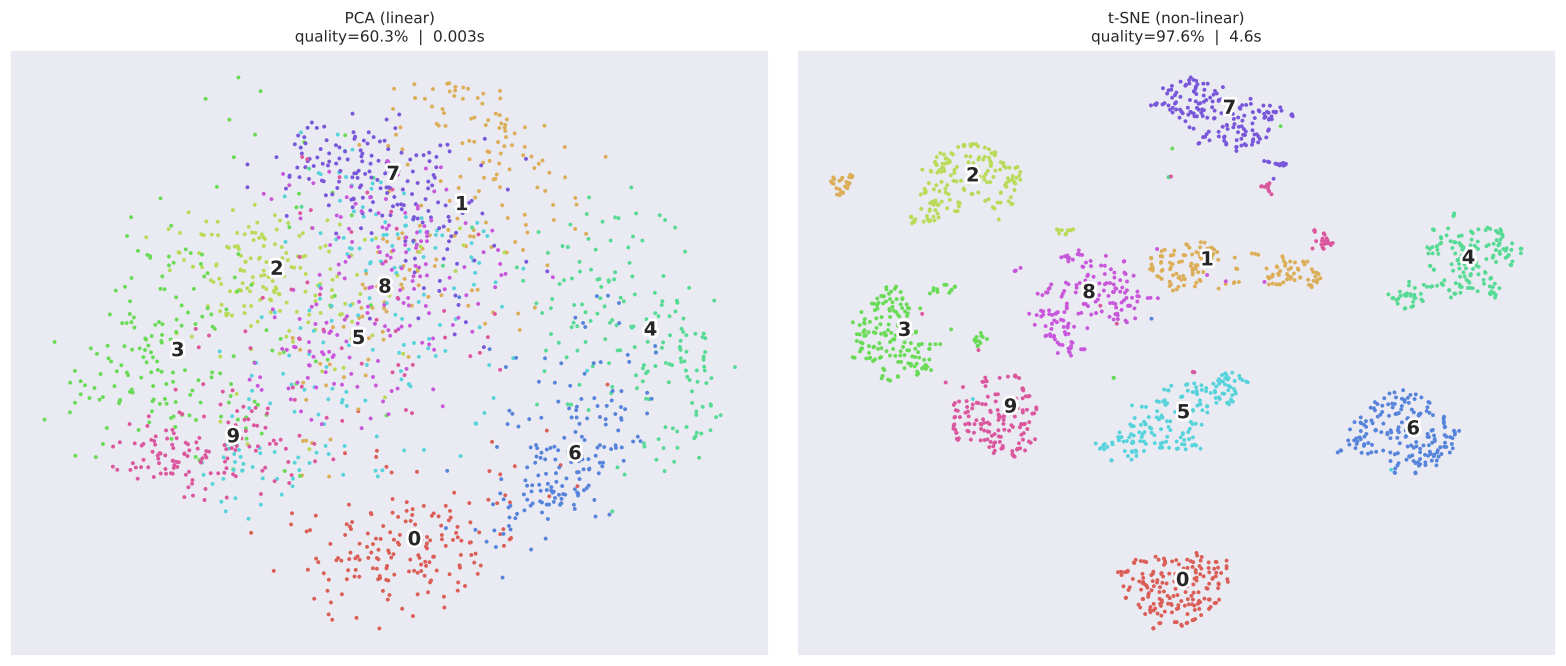

Original 64 pixels  -> cluster quality = 96.3%
PCA,   2 dimensions -> cluster quality = 60.3%   time = 0.003 s
t-SNE, 2 dimensions -> cluster quality = 97.6%   time = 4.6 s


In [ ]:
start = time.time(); pca_proj = PCA(n_components=2).fit_transform(X); pca_time = time.time() - start
start = time.time(); tsne_proj = TSNE(init="pca", random_state=RS).fit_transform(X); tsne_time = time.time() - start

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
small_scatter(axes[0], pca_proj, y, f"PCA (linear)\nquality={cluster_quality(pca_proj, y)*100:.1f}%  |  {pca_time:.3f}s")
small_scatter(axes[1], tsne_proj, y, f"t-SNE (non-linear)\nquality={cluster_quality(tsne_proj, y)*100:.1f}%  |  {tsne_time:.1f}s")
plt.tight_layout()
plt.show()

print(f"Original 64 pixels  -> cluster quality = {cluster_quality(X, y)*100:.1f}%")
print(f"PCA,   2 dimensions -> cluster quality = {cluster_quality(pca_proj, y)*100:.1f}%   time = {pca_time:.3f} s")
print(f"t-SNE, 2 dimensions -> cluster quality = {cluster_quality(tsne_proj, y)*100:.1f}%   time = {tsne_time:.1f} s")

**Answer:**

From my experiment on the 1797 digits: in PCA's 2D picture most digits overlap in one big cloud (cluster quality **60.3%**), while t-SNE separates all 10 digits into clear clusters (**97.6%**). That's even slightly better than using all 64 original pixels (96.3%). But PCA took **0.003 s** and t-SNE about **4.6 s**, more than 1000 times slower.

**a. Linear or non-linear?**
**PCA is linear**: each new axis is a fixed weighted sum of the original features, so it can only rotate, stretch and flatten the data. **t-SNE is non-linear**: it can move every point freely to wherever best matches its neighbourhood.

**b. How does non-linearity help?**
Real data like handwritten digits doesn't lie on a flat plane. Each digit forms a curved, twisted region in the 64-dimensional pixel space. A straight-line projection (PCA) squashes these regions on top of each other, which is why the PCA plot looks like one mixed cloud. Because t-SNE is non-linear, it can "unfold" these curved regions and place each group in its own area of the 2D map, so clusters that were mixed up in PCA become clearly separated.

**c. Does t-SNE preserve far-apart distances like PCA?**
No. **PCA preserves global structure**: it keeps the directions of largest variance, so points that are far apart in the original space generally stay far apart. **t-SNE preserves local neighbourhoods**: it makes sure points that were close stay close, but it uses a heavy-tailed t-distribution in 2D, which deliberately pushes dissimilar points far away. So in a t-SNE plot:
- points inside a cluster being close **is** meaningful,
- but the **distance between two clusters, and the size of a cluster, are not reliable**. Two clusters far apart on the map are not necessarily very different.

**d. Which is more computationally expensive?**
**t-SNE is much more expensive.** PCA solves one eigenvalue problem, in about O(N·D² + D³) time, and it's done (0.003 s here). t-SNE compares pairs of points and then runs gradient descent for about 1000 iterations: O(N²) per iteration for the exact method, or O(N log N) with the Barnes-Hut approximation (about 4.6 s here).

**Summary of advantages and disadvantages:**

| | PCA | t-SNE |
|---|---|---|
| Type | Linear | Non-linear |
| Preserves | Global structure / variance | Local neighbourhoods |
| Speed | Very fast | Slow |
| Same result every run? | Yes (deterministic) | No, depends on random seed |
| New data points | Easy: `pca.transform(new_data)` | Not possible, must re-run on all data |
| Meaning of axes | Clear (directions of variance) | None |
| Choosing dimensions | Explained variance | Usually just 2 or 3 |
| Separating clusters for visualisation | Weak (60.3% here) | Excellent (97.6% here) |
| Use as input to other ML models | Yes | Not recommended |

**When to use which:** use **PCA** for fast dimensionality reduction, noise removal, and as a pre-processing step for ML models. Use **t-SNE** for **visualising** and exploring clusters in high-dimensional data. A common recipe is to reduce to about 50 dimensions with PCA first, then run t-SNE on that.

### Question 2: How does the computational complexity and runtime of t-SNE scale with dataset size and dimensionality?

Experiment: time t-SNE (Barnes-Hut and exact) and PCA on more and more points, then on data with more and more dimensions. To get more than 1797 points, I add slightly noisy copies of the digit images.

*This cell takes about 2–3 minutes to run.*

N =  250 points | Barnes-Hut =   0.8s | exact =    3.1s | PCA = 0.0038s


N =  500 points | Barnes-Hut =   1.7s | exact =    6.1s | PCA = 0.0025s


N = 1000 points | Barnes-Hut =   3.1s | exact =   22.4s | PCA = 0.0023s


N = 2000 points | Barnes-Hut =   6.9s | exact =   (skipped) | PCA = 0.0049s


N = 4000 points | Barnes-Hut =  17.4s | exact =   (skipped) | PCA = 0.0035s



D =   64 dimensions (N = 1000) | Barnes-Hut time = 3.0s


D =  512 dimensions (N = 1000) | Barnes-Hut time = 2.6s


D = 2048 dimensions (N = 1000) | Barnes-Hut time = 3.0s


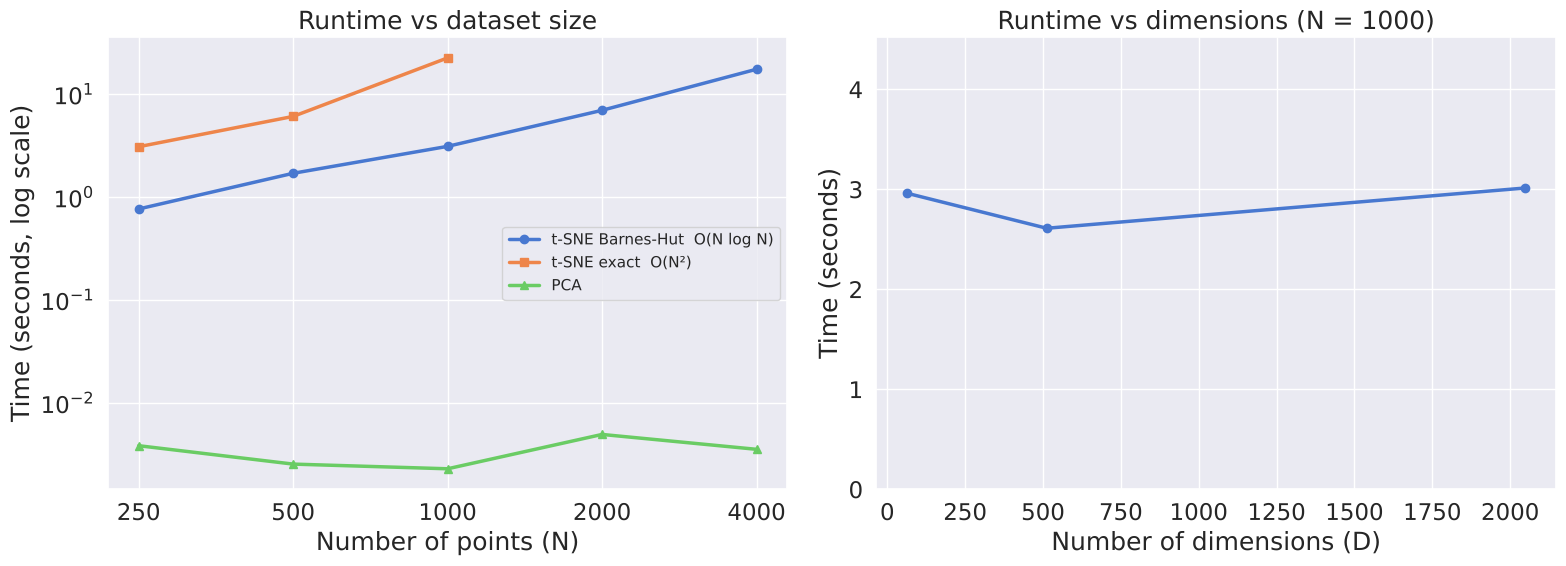

In [ ]:
rng = np.random.default_rng(0)
# Make a bigger dataset: 4 slightly noisy copies of the 1797 images (7188 images)
X_big = np.vstack([digits.data + rng.normal(0, 0.5, digits.data.shape) for _ in range(4)])

sizes = [250, 500, 1000, 2000, 4000]
bh_times, exact_times, pca_times = [], [], []
for n in sizes:
    data_n = X_big[:n]
    start = time.time(); TSNE(init="pca", random_state=RS).fit_transform(data_n); bh_times.append(time.time() - start)
    if n <= 1000:   # exact is too slow beyond this
        start = time.time(); TSNE(init="pca", random_state=RS, method="exact").fit_transform(data_n); exact_times.append(time.time() - start)
    start = time.time(); PCA(n_components=2).fit_transform(data_n); pca_times.append(time.time() - start)
    exact_txt = f"{exact_times[-1]:6.1f}s" if n <= 1000 else "  (skipped)"
    print(f"N = {n:>4} points | Barnes-Hut = {bh_times[-1]:5.1f}s | exact = {exact_txt} | PCA = {pca_times[-1]:.4f}s")

# Effect of dimensionality: same 1000 images, padded with extra random columns
print()
dims = [64, 512, 2048]
dim_times = []
for D in dims:
    data_d = X[:1000] if D == 64 else np.hstack([X[:1000], rng.normal(0, 1, (1000, D - 64))])
    start = time.time(); TSNE(init="pca", random_state=RS).fit_transform(data_d); dim_times.append(time.time() - start)
    print(f"D = {D:>4} dimensions (N = 1000) | Barnes-Hut time = {dim_times[-1]:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].plot(sizes, bh_times, "o-", label="t-SNE Barnes-Hut  O(N log N)")
axes[0].plot(sizes[:len(exact_times)], exact_times, "s-", label="t-SNE exact  O(N²)")
axes[0].plot(sizes, pca_times, "^-", label="PCA")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xticks(sizes); axes[0].set_xticklabels([str(s) for s in sizes]); axes[0].minorticks_off()
axes[0].set_xlabel("Number of points (N)"); axes[0].set_ylabel("Time (seconds, log scale)")
axes[0].set_title("Runtime vs dataset size"); axes[0].legend(fontsize=11)

axes[1].plot(dims, dim_times, "o-")
axes[1].set_xlabel("Number of dimensions (D)"); axes[1].set_ylabel("Time (seconds)")
axes[1].set_ylim(0, max(dim_times) * 1.5)
axes[1].set_title("Runtime vs dimensions (N = 1000)")
plt.tight_layout()
plt.show()

**Answer:**

**Dataset size (N): the main factor.**

| Points (N) | Barnes-Hut | Exact | PCA |
|---|---|---|---|
| 250 | 0.8 s | 3.1 s | 0.004 s |
| 500 | 1.7 s | 6.1 s | 0.003 s |
| 1000 | 3.1 s | 22.4 s | 0.002 s |
| 2000 | 6.9 s | (too slow) | 0.005 s |
| 4000 | 17.4 s | (too slow) | 0.004 s |

- **Exact t-SNE is O(N²)** in time and memory: it computes the similarity between **every pair** of points (an N × N matrix) in every iteration. Going from 500 to 1000 points made it about **3.7× slower** (6.1 s to 22.4 s). At 2000 points it took about 95 s in an earlier test, so I skipped it here. For 100,000 points it would need a 100,000 × 100,000 matrix, which is impossible on normal hardware.
- **Barnes-Hut t-SNE is O(N log N)**: it only computes exact similarities for nearby points (about 3 × perplexity neighbours) and groups far-away points together using a tree (a quad-tree in 2D). Doubling N roughly doubles the time (3.1 s, 6.9 s, 17.4 s). That's why it's the default and why sklearn only allows it for 2 or 3 output dimensions.
- **PCA** stayed at a few milliseconds the whole time.
- Runtime also grows linearly with the **number of iterations** (about 1000), and higher **perplexity** is slower because each point has more neighbours (2.6 s at perplexity 100 vs 1.0 s at 2, for 250 iterations, in the grid above).

**Dimensionality (D): a much smaller effect.**
Going from 64 to 2048 input dimensions with N = 1000 barely changed the time (3.0 s, 2.6 s, 3.0 s). The input dimensions are only used **once**, to compute the distances between points, which costs about O(N·D) for the neighbour search, or O(N²·D) for the exact method. All the expensive gradient-descent iterations happen in the small **output space** (2D), so they don't depend on D. For very high-dimensional data (e.g. thousands of features and many points), distance computation does become slower and distances become less meaningful (the "curse of dimensionality"). That's why the usual practice is to first reduce the data to about **50 dimensions with PCA**, then run t-SNE.

**Summary:** exact t-SNE is **O(N²)**, Barnes-Hut is **O(N log N)**. Both scale linearly with the number of iterations, and depend on the input dimensions D only through the one-time distance calculation.

### Question 3: What are some limitations or potential pitfalls to be aware of when using t-SNE?

Experiment: run t-SNE on the same data with 3 different random seeds.

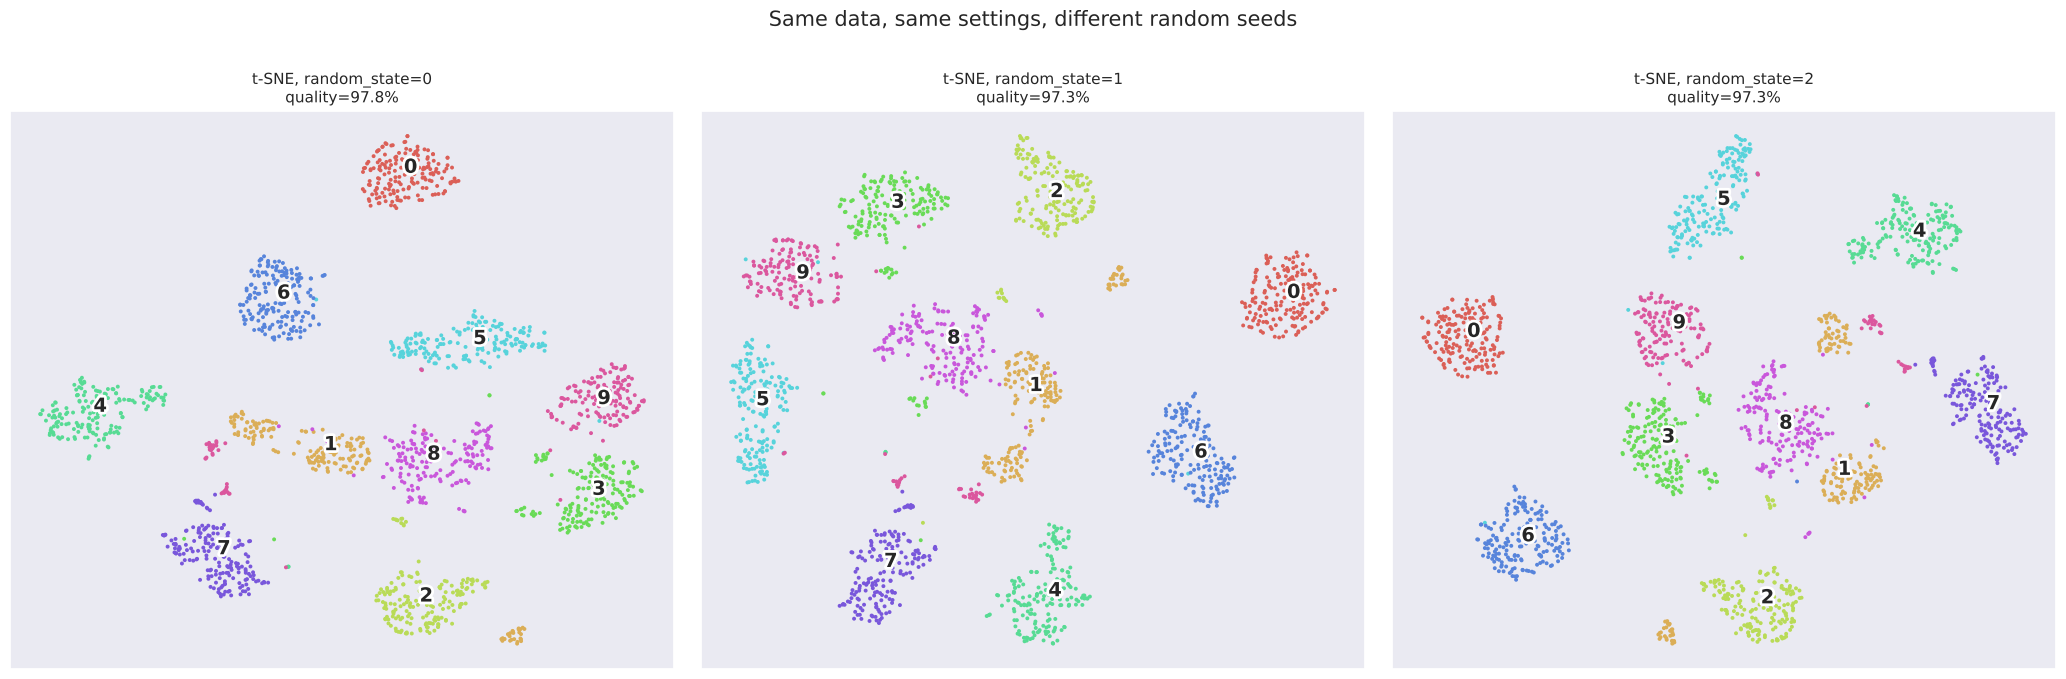

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, seed in zip(axes, [0, 1, 2]):
    proj = TSNE(init="random", random_state=seed).fit_transform(X)
    small_scatter(ax, proj, y, f"t-SNE, random_state={seed}\nquality={cluster_quality(proj, y)*100:.1f}%")
plt.suptitle("Same data, same settings, different random seeds", fontsize=15)
plt.tight_layout()
plt.show()

**Answer:**

In the experiment above, all three runs used the same data and settings. Each run separates the digits equally well (quality 97.3–97.8%), but the **maps look completely different**: digit 0 is at the top in one, on the right in another, on the left in the third, and the neighbouring clusters change too.

Limitations and pitfalls of t-SNE:

1. **Results change from run to run (random / non-deterministic).** t-SNE starts from a random layout and uses gradient descent, so different random seeds give different maps (as shown above). You should fix `random_state` to reproduce a result, and check that a pattern appears across several runs before trusting it.
2. **Cluster sizes and distances between clusters are not meaningful.** t-SNE expands dense clusters and shrinks sparse ones, and the gap between two clusters doesn't measure how different they are. In the seed experiment, the cluster next to digit 0 changes every run. Only "which points are close to which" can be trusted.
3. **Very sensitive to hyperparameters.** Perplexity and the number of iterations can completely change the picture: perplexity 2 made one big cloud, perplexity 100 with 250 iterations merged several digits. There's no single correct value, so you have to try several.
4. **Stopping too early gives misleading shapes.** With 250 iterations the clusters were squashed into thin lines (shown in the grid above). The optimisation must run until the layout is stable.
5. **Slow and memory-heavy on large datasets.** Exact t-SNE is O(N²) and Barnes-Hut is O(N log N), compared with milliseconds for PCA (Question 2). For very large datasets, UMAP or PCA-then-t-SNE is often used instead.
6. **Can't transform new data.** t-SNE has no `transform()` for new points. Adding even one new image means re-running on the whole dataset, so it can't be used as a normal pre-processing step for a model.
7. **Can show "clusters" in random noise.** With low perplexity, t-SNE can make clumps appear even in data with no real groups. Small sub-clusters (like the small islands of 1s and 3s) need to be checked before being interpreted.
8. **Only for visualisation, not feature reduction.** The output axes have no meaning, and sklearn's fast method only supports 2 or 3 dimensions, so it's not suitable for reducing features before training a model. PCA is better for that.

**In short:** t-SNE is excellent for **looking at** clusters, but its plots must be read carefully. Trust which points group together, not the sizes, positions or distances between clusters, and always compare several runs and perplexity values.



---
 ## Some interesting references:

 1. https://blog.paperspace.com/dimension-reduction-with-t-sne/
 2. https://towardsdatascience.com/an-introduction-to-t-sne-with-python-example-5a3a293108d1
 3. https://distill.pub/2016/misread-tsne/



---


